# **1: KNN Model**

📊 Evaluation Metrics:
Accuracy : 0.8981
Precision: 0.9014
Recall   : 0.9437
F1-score : 0.9221
Log Loss : 0.8858
ROC AUC  : 0.9400


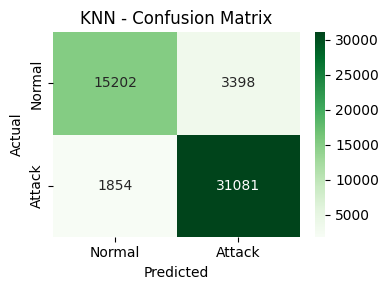

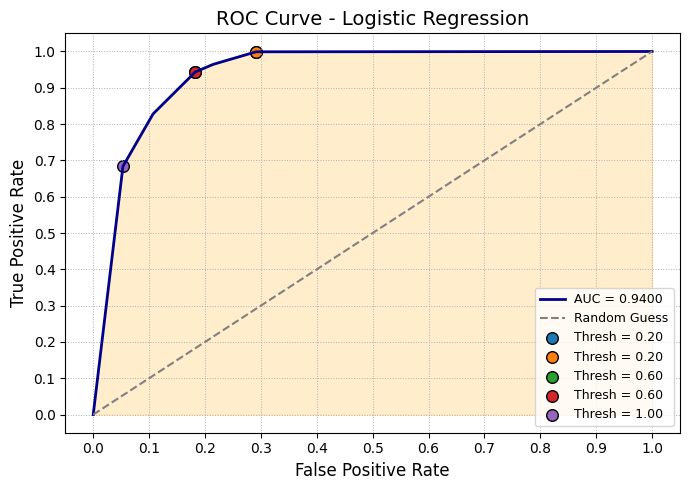

In [ ]:
# === STEP 1: IMPORT LIBRARIES ===
import torch
import random
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, log_loss, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # if using multi-GPU
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# === STEP 2: LOAD DATA ===
train_df = pd.read_csv("/content/UNSW_NB15_training-set.csv", sep=',')
test_df = pd.read_csv("/content/UNSW_NB15_testing-set.csv", sep=',')

# === STEP 3: COMBINE DATA ===
df = pd.concat([train_df, test_df], ignore_index=True)

# === STEP 4: SELECT IoT-RELEVANT FEATURES ===
iot_features = [
    'dur', 'proto', 'service', 'state',
    'spkts', 'dpkts', 'sbytes', 'dbytes',
    'rate', 'sttl', 'dttl',
    'sload', 'dload', 'sloss', 'dloss',
    'sinpkt', 'dinpkt', 'sjit', 'djit',
    'ct_state_ttl', 'ct_dst_ltm', 'ct_srv_dst',
    'is_sm_ips_ports', 'label'
]

missing = set(iot_features) - set(df.columns)
if missing:
    raise ValueError(f"Missing features in dataset: {missing}")

df = df[iot_features]

# === STEP 5: CLEAN, ENCODE & DROP NA ===
df = df.dropna()
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col].astype(str))

# === STEP 6: SEPARATE FEATURES & LABELS ===
X = df.drop('label', axis=1).values
y = df['label'].values

# === STEP 7: SCALE FEATURES ===
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# === STEP 8: ADD LIGHT GAUSSIAN NOISE ===
def add_light_noise(data, std=0.1):
    noise = np.random.normal(loc=0.0, scale=std, size=data.shape)
    return np.clip(data + noise, 0.0, 1.0)

# === STEP 8: SPLIT SETS ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)
X_train_noisy = add_light_noise(X_train)
# === STEP 9: TRAIN KNN MODEL ===
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_noisy, y_train)

# === STEP 10: PREDICT & EVALUATE ===
y_pred = knn_model.predict(X_test)
y_prob = knn_model.predict_proba(X_test)[:, 1]  # Probability for positive class

print("📊 Evaluation Metrics:")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"Log Loss : {log_loss(y_test, y_prob):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")

# === STEP 11: CONFUSION MATRIX HEATMAP ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# === STEP 12: ROC CURVE (Improved with Threshold Markers) ===
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkblue', linewidth=2, label=f'AUC = {auc_score:.4f}')
plt.fill_between(fpr, tpr, alpha=0.2, color='orange')

# Add diagonal reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, label='Random Guess')

# Add threshold markers
for thresh_val in [0.1, 0.3, 0.5, 0.7, 0.9]:
    idx = np.argmin(np.abs(thresholds - thresh_val))
    plt.scatter(fpr[idx], tpr[idx], s=70, edgecolors='black', label=f'Thresh = {thresholds[idx]:.2f}')

# Labels and formatting
plt.title('ROC Curve - Logistic Regression', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.xticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.yticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.grid(True, linestyle=':', linewidth=0.7)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()


In [ ]:
89,89

# **2: Decision Tree Classifier Model**

📊 Evaluation Metrics:
Accuracy : 0.9099
Precision: 0.9004
Recall   : 0.9659
F1-score : 0.9320
Log Loss : 0.1689
ROC AUC  : 0.9792


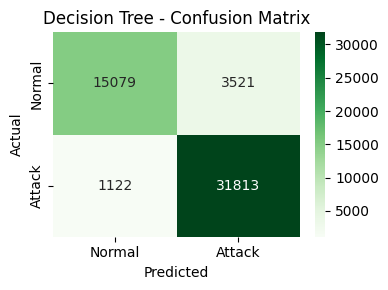

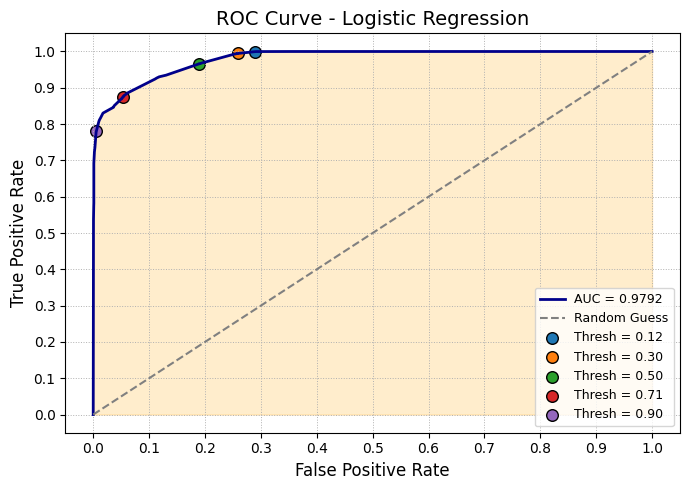

In [ ]:
# === STEP 1: IMPORT LIBRARIES ===
import torch
import random
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, log_loss, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# === STEP 2: LOAD DATA ===
train_df = pd.read_csv("/content/UNSW_NB15_training-set.csv", sep=',')
test_df = pd.read_csv("/content/UNSW_NB15_testing-set.csv", sep=',')

# === STEP 3: COMBINE DATA ===
df = pd.concat([train_df, test_df], ignore_index=True)

# === STEP 4: SELECT IoT-RELEVANT FEATURES ===
iot_features = [
    'dur', 'proto', 'service', 'state',
    'spkts', 'dpkts', 'sbytes', 'dbytes',
    'rate', 'sttl', 'dttl',
    'sload', 'dload', 'sloss', 'dloss',
    'sinpkt', 'dinpkt', 'sjit', 'djit',
    'ct_state_ttl', 'ct_dst_ltm', 'ct_srv_dst',
    'is_sm_ips_ports', 'label'
]

missing = set(iot_features) - set(df.columns)
if missing:
    raise ValueError(f"Missing features in dataset: {missing}")

df = df[iot_features]

# === STEP 5: CLEAN, ENCODE & DROP NA ===
df = df.dropna()
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col].astype(str))

# === STEP 6: SEPARATE FEATURES & LABELS ===
X = df.drop('label', axis=1).values
y = df['label'].values

# === STEP 7: SCALE FEATURES ===
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# === STEP 8: ADD LIGHT GAUSSIAN NOISE ===
def add_light_noise(data, std=0.005):
    noise = np.random.normal(loc=0.0, scale=std, size=data.shape)
    return np.clip(data + noise, 0.0, 1.0)

# === STEP 9: SPLIT DATA ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)
X_train_noisy = add_light_noise(X_train)

# === STEP 10: TRAIN DECISION TREE ===
dt_model = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_model.fit(X_train_noisy, y_train)

# === STEP 11: PREDICT & EVALUATE ===
y_pred = dt_model.predict(X_test)
y_prob = dt_model.predict_proba(X_test)[:, 1]

print("📊 Evaluation Metrics:")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"Log Loss : {log_loss(y_test, y_prob):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")

# === STEP 12: CONFUSION MATRIX ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# === STEP 12: ROC CURVE (Improved with Threshold Markers) ===
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkblue', linewidth=2, label=f'AUC = {auc_score:.4f}')
plt.fill_between(fpr, tpr, alpha=0.2, color='orange')

# Add diagonal reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, label='Random Guess')

# Add threshold markers
for thresh_val in [0.1, 0.3, 0.5, 0.7, 0.9]:
    idx = np.argmin(np.abs(thresholds - thresh_val))
    plt.scatter(fpr[idx], tpr[idx], s=70, edgecolors='black', label=f'Thresh = {thresholds[idx]:.2f}')

# Labels and formatting
plt.title('ROC Curve - Logistic Regression', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.xticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.yticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.grid(True, linestyle=':', linewidth=0.7)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
90,90

# **3: Naive Bayes Model**

📊 Evaluation Metrics:
Accuracy : 0.8656
Precision: 0.8470
Recall   : 0.9638
F1-score : 0.9016
Log Loss : 1.3162
ROC AUC  : 0.8945


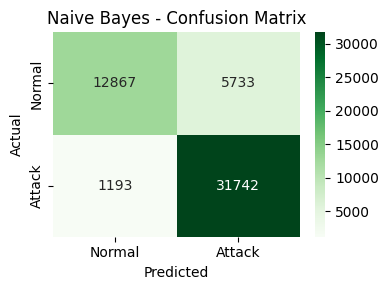

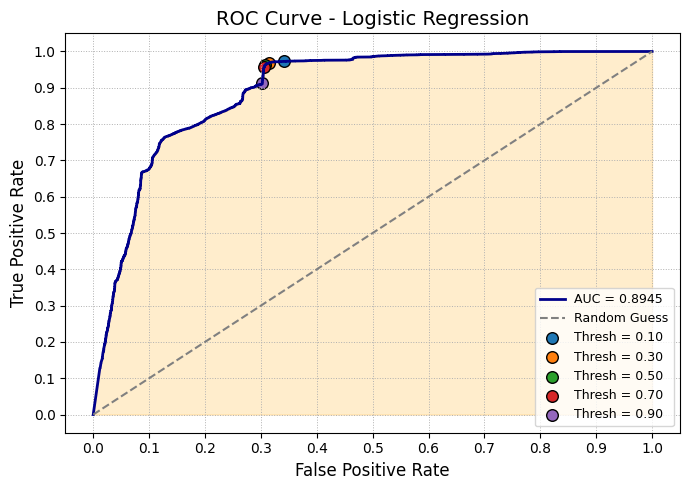

In [ ]:
# === STEP 1: IMPORT LIBRARIES ===
import torch
import random
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, log_loss, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# === STEP 2: LOAD DATA ===
train_df = pd.read_csv("/content/UNSW_NB15_training-set.csv", sep=',')
test_df = pd.read_csv("/content/UNSW_NB15_testing-set.csv", sep=',')

# === STEP 3: COMBINE DATA ===
df = pd.concat([train_df, test_df], ignore_index=True)

# === STEP 4: SELECT IoT-RELEVANT FEATURES ===
iot_features = [
    'dur', 'proto', 'service', 'state',
    'spkts', 'dpkts', 'sbytes', 'dbytes',
    'rate', 'sttl', 'dttl',
    'sload', 'dload', 'sloss', 'dloss',
    'sinpkt', 'dinpkt', 'sjit', 'djit',
    'ct_state_ttl', 'ct_dst_ltm', 'ct_srv_dst',
    'is_sm_ips_ports', 'label'
]

missing = set(iot_features) - set(df.columns)
if missing:
    raise ValueError(f"Missing features in dataset: {missing}")

df = df[iot_features]

# === STEP 5: CLEAN, ENCODE & DROP NA ===
df = df.dropna()
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col].astype(str))

# === STEP 6: SEPARATE FEATURES & LABELS ===
X = df.drop('label', axis=1).values
y = df['label'].values

# === STEP 7: SCALE FEATURES ===
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# === STEP 8: ADD LIGHT GAUSSIAN NOISE ===
def add_light_noise(data, std=0.005):
    noise = np.random.normal(loc=0.0, scale=std, size=data.shape)
    return np.clip(data + noise, 0.0, 1.0)

# === STEP 9: SPLIT DATA ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)
X_train_noisy = add_light_noise(X_train)

# === STEP 10: TRAIN NAIVE BAYES ===
nb_model = GaussianNB()
nb_model.fit(X_train_noisy, y_train)

# === STEP 11: PREDICT & EVALUATE ===
y_pred = nb_model.predict(X_test)
y_prob = nb_model.predict_proba(X_test)[:, 1]

print("📊 Evaluation Metrics:")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"Log Loss : {log_loss(y_test, y_prob):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")

# === STEP 12: CONFUSION MATRIX ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# === STEP 12: ROC CURVE (Improved with Threshold Markers) ===
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkblue', linewidth=2, label=f'AUC = {auc_score:.4f}')
plt.fill_between(fpr, tpr, alpha=0.2, color='orange')

# Add diagonal reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, label='Random Guess')

# Add threshold markers
for thresh_val in [0.1, 0.3, 0.5, 0.7, 0.9]:
    idx = np.argmin(np.abs(thresholds - thresh_val))
    plt.scatter(fpr[idx], tpr[idx], s=70, edgecolors='black', label=f'Thresh = {thresholds[idx]:.2f}')

# Labels and formatting
plt.title('ROC Curve - Logistic Regression', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.xticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.yticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.grid(True, linestyle=':', linewidth=0.7)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
86,86

# **4: Logestic Regression Model**

📊 Evaluation Metrics:
Accuracy : 0.8525
Precision: 0.8331
Recall   : 0.9619
F1-score : 0.8929
Log Loss : 0.3534
ROC AUC  : 0.9040


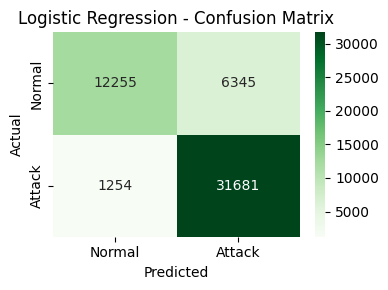

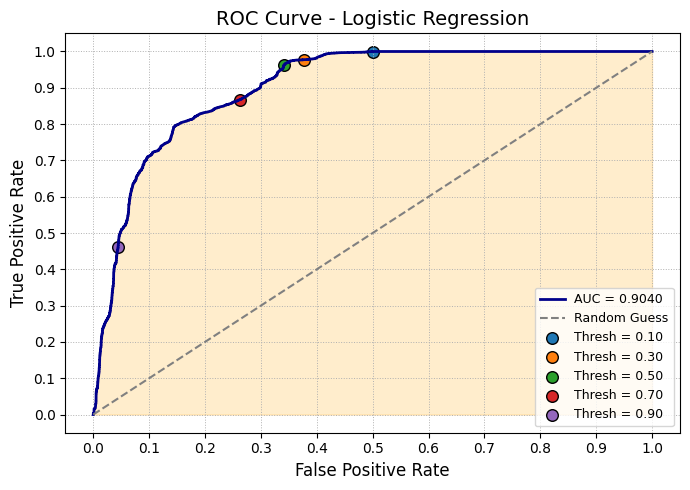

In [ ]:
# === STEP 1: IMPORT LIBRARIES ===
import torch
import random
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, log_loss, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# === STEP 2: LOAD DATA ===
train_df = pd.read_csv("/content/UNSW_NB15_training-set.csv", sep=',')
test_df = pd.read_csv("/content/UNSW_NB15_testing-set.csv", sep=',')

# === STEP 3: COMBINE DATA ===
df = pd.concat([train_df, test_df], ignore_index=True)

# === STEP 4: SELECT IoT-RELEVANT FEATURES ===
iot_features = [
    'dur', 'proto', 'service', 'state',
    'spkts', 'dpkts', 'sbytes', 'dbytes',
    'rate', 'sttl', 'dttl',
    'sload', 'dload', 'sloss', 'dloss',
    'sinpkt', 'dinpkt', 'sjit', 'djit',
    'ct_state_ttl', 'ct_dst_ltm', 'ct_srv_dst',
    'is_sm_ips_ports', 'label'
]

missing = set(iot_features) - set(df.columns)
if missing:
    raise ValueError(f"Missing features in dataset: {missing}")

df = df[iot_features]

# === STEP 5: CLEAN, ENCODE & DROP NA ===
df = df.dropna()
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col].astype(str))

# === STEP 6: SEPARATE FEATURES & LABELS ===
X = df.drop('label', axis=1).values
y = df['label'].values

# === STEP 7: SCALE FEATURES ===
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# === STEP 8: SPLIT DATA ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)

# === STEP 9: TRAIN LOGISTIC REGRESSION ===
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# === STEP 10: PREDICT & EVALUATE ===
y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:, 1]

print("📊 Evaluation Metrics:")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"Log Loss : {log_loss(y_test, y_prob):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")

# === STEP 11: CONFUSION MATRIX ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# === STEP 12: ROC CURVE (Improved with Threshold Markers) ===
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkblue', linewidth=2, label=f'AUC = {auc_score:.4f}')
plt.fill_between(fpr, tpr, alpha=0.2, color='orange')

# Add diagonal reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, label='Random Guess')

# Add threshold markers
for thresh_val in [0.1, 0.3, 0.5, 0.7, 0.9]:
    idx = np.argmin(np.abs(thresholds - thresh_val))
    plt.scatter(fpr[idx], tpr[idx], s=70, edgecolors='black', label=f'Thresh = {thresholds[idx]:.2f}')

# Labels and formatting
plt.title('ROC Curve - Logistic Regression', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.xticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.yticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.grid(True, linestyle=':', linewidth=0.7)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()



In [ ]:
85,85

# **5: Random Forest Classifier Model**

📊 Evaluation Metrics:
Accuracy : 0.9073
Precision: 0.9438
Recall   : 0.9091
F1-score : 0.9261
Log Loss : 0.1840
ROC AUC  : 0.9778


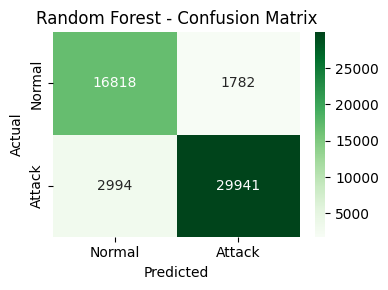

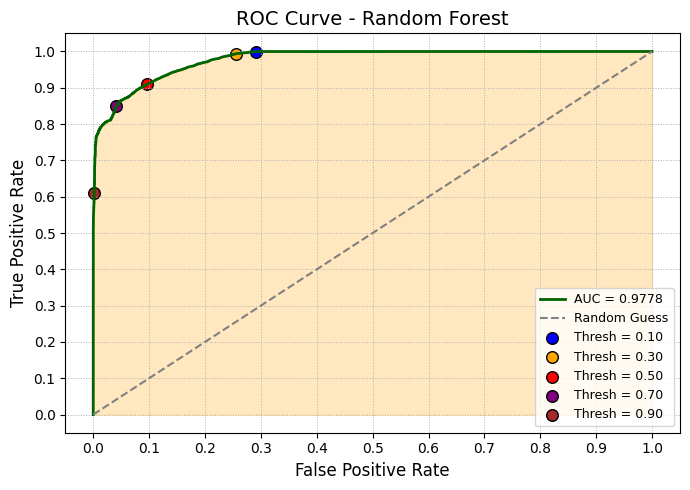

In [ ]:
# === STEP 1: IMPORT LIBRARIES ===
import torch
import random
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, log_loss, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# === STEP 2: LOAD DATA ===
train_df = pd.read_csv("/content/UNSW_NB15_training-set.csv", sep=',')
test_df = pd.read_csv("/content/UNSW_NB15_testing-set.csv", sep=',')

# === STEP 3: COMBINE DATA ===
df = pd.concat([train_df, test_df], ignore_index=True)

# === STEP 4: SELECT IoT-RELEVANT FEATURES ===
iot_features = [
    'dur', 'proto', 'service', 'state',
    'spkts', 'dpkts', 'sbytes', 'dbytes',
    'rate', 'sttl', 'dttl',
    'sload', 'dload', 'sloss', 'dloss',
    'sinpkt', 'dinpkt', 'sjit', 'djit',
    'ct_state_ttl', 'ct_dst_ltm', 'ct_srv_dst',
    'is_sm_ips_ports', 'label'
]

missing = set(iot_features) - set(df.columns)
if missing:
    raise ValueError(f"Missing features in dataset: {missing}")

df = df[iot_features]

# === STEP 5: CLEAN, ENCODE & DROP NA ===
df = df.dropna()
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col].astype(str))

# === STEP 6: SEPARATE FEATURES & LABELS ===
X = df.drop('label', axis=1).values
y = df['label'].values

# === STEP 7: SCALE FEATURES ===
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# === STEP 8: SPLIT DATA ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)

# === STEP 8.1: ADD NOISE TO TRAINING FEATURES ===
noise_strength = 0.01
X_train_noisy = X_train + np.random.normal(loc=0.0, scale=noise_strength, size=X_train.shape)

# === STEP 9: TRAIN RANDOM FOREST ===
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_noisy, y_train)

# === STEP 10: PREDICT & EVALUATE ===
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("📊 Evaluation Metrics:")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"Log Loss : {log_loss(y_test, y_prob):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")

# === STEP 11: CONFUSION MATRIX ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# === STEP 12: ROC CURVE WITH THRESHOLD MARKERS ===
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkgreen', linewidth=2, label=f'AUC = {auc_score:.4f}')
plt.fill_between(fpr, tpr, alpha=0.25, color='orange')

# Diagonal reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, label='Random Guess')

# Threshold markers
colors = ['blue', 'orange', 'red', 'purple', 'brown']
for thresh_val, color in zip([0.1, 0.3, 0.5, 0.7, 0.9], colors):
    idx = np.argmin(np.abs(thresholds - thresh_val))
    plt.scatter(fpr[idx], tpr[idx], s=70, edgecolors='black', color=color, label=f'Thresh = {thresholds[idx]:.2f}')

plt.title('ROC Curve - Random Forest', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.xticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.yticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.grid(True, linestyle=':', linewidth=0.7)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()


In [ ]:
90,90

# **6: XGBoost Model**

📊 Evaluation Metrics:
Accuracy : 0.9113
Precision: 0.9223
Recall   : 0.9405
F1-score : 0.9313
Log Loss : 0.1715
ROC AUC  : 0.9784


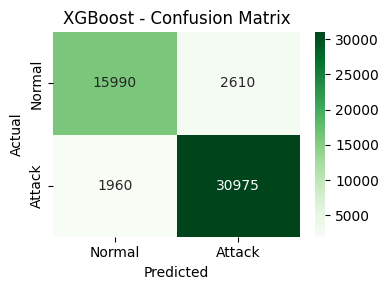

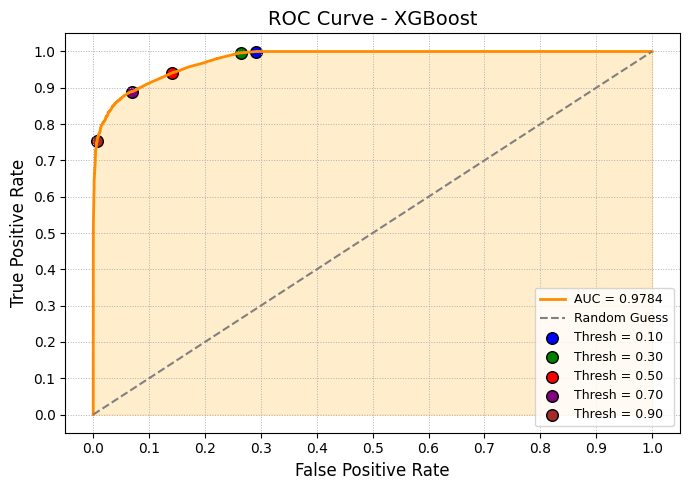

In [ ]:
# === STEP 1: IMPORT LIBRARIES ===
import torch
import random
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, log_loss, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

# Set random seed for reproducibility
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# === STEP 2: LOAD DATA ===
train_df = pd.read_csv("/content/UNSW_NB15_training-set.csv", sep=',')
test_df = pd.read_csv("/content/UNSW_NB15_testing-set.csv", sep=',')

# === STEP 3: COMBINE DATA ===
df = pd.concat([train_df, test_df], ignore_index=True)

# === STEP 4: SELECT IoT-RELEVANT FEATURES ===
iot_features = [
    'dur', 'proto', 'service', 'state',
    'spkts', 'dpkts', 'sbytes', 'dbytes',
    'rate', 'sttl', 'dttl',
    'sload', 'dload', 'sloss', 'dloss',
    'sinpkt', 'dinpkt', 'sjit', 'djit',
    'ct_state_ttl', 'ct_dst_ltm', 'ct_srv_dst',
    'is_sm_ips_ports', 'label'
]

missing = set(iot_features) - set(df.columns)
if missing:
    raise ValueError(f"Missing features in dataset: {missing}")
df = df[iot_features]

# === STEP 5: CLEAN, ENCODE & DROP NA ===
df = df.dropna()
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col].astype(str))

# === STEP 6: SEPARATE FEATURES & LABELS ===
X = df.drop('label', axis=1).values
y = df['label'].values

# === STEP 7: SCALE FEATURES ===
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# === STEP 8: SPLIT DATA ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)

# === STEP 8.1: ADD NOISE TO TRAINING FEATURES ===
noise_strength = 0.01
X_train_noisy = X_train + np.random.normal(loc=0.0, scale=noise_strength, size=X_train.shape)

# === STEP 9: TRAIN XGBOOST ===
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_noisy, y_train)

# === STEP 10: PREDICT & EVALUATE ===
y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

print("📊 Evaluation Metrics:")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"Log Loss : {log_loss(y_test, y_prob):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")

# === STEP 11: CONFUSION MATRIX ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.title("XGBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# === STEP 12: ROC CURVE WITH THRESHOLD MARKERS ===
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', linewidth=2, label=f'AUC = {auc_score:.4f}')
plt.fill_between(fpr, tpr, alpha=0.2, color='orange')

# Diagonal reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, label='Random Guess')

# Threshold markers
colors = ['blue', 'green', 'red', 'purple', 'brown']
for thresh_val, color in zip([0.1, 0.3, 0.5, 0.7, 0.9], colors):
    idx = np.argmin(np.abs(thresholds - thresh_val))
    plt.scatter(fpr[idx], tpr[idx], s=70, edgecolors='black', color=color, label=f'Thresh = {thresholds[idx]:.2f}')

plt.title('ROC Curve - XGBoost', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.xticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.yticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.grid(True, linestyle=':', linewidth=0.7)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()


In [ ]:
91,91

# **7: SVM Model**

📊 Evaluation Metrics:
Accuracy : 0.8972
Precision: 0.8674
Recall   : 0.9906
F1-score : 0.9249
Log Loss : 0.2261
ROC AUC  : 0.9705


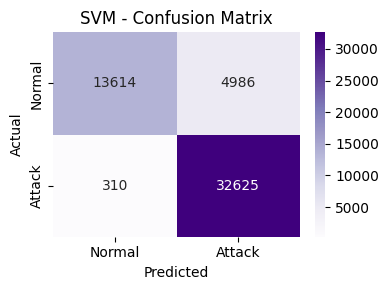

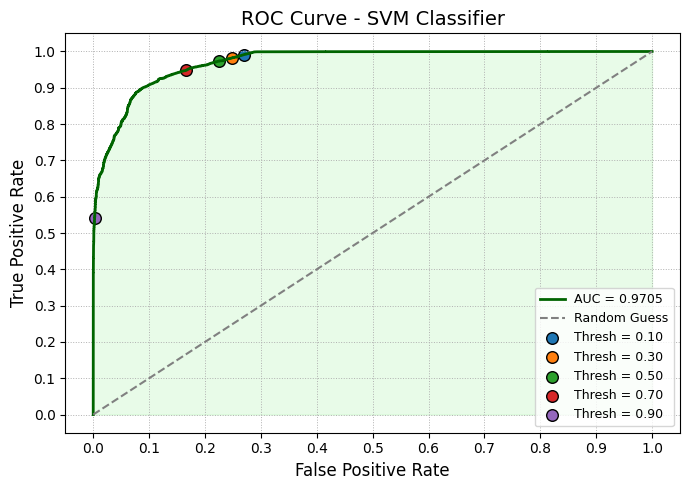

In [ ]:
# === STEP 1: IMPORT LIBRARIES ===
import torch
import random
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, log_loss, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # if using multi-GPU
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# === STEP 2: LOAD DATA ===
train_df = pd.read_csv("/content/UNSW_NB15_training-set.csv", sep=',')
test_df = pd.read_csv("/content/UNSW_NB15_testing-set.csv", sep=',')

# === STEP 3: COMBINE DATA ===
df = pd.concat([train_df, test_df], ignore_index=True)

# === STEP 4: SELECT IoT-RELEVANT FEATURES ===
iot_features = [
    'dur', 'proto', 'service', 'state',
    'spkts', 'dpkts', 'sbytes', 'dbytes',
    'rate', 'sttl', 'dttl',
    'sload', 'dload', 'sloss', 'dloss',
    'sinpkt', 'dinpkt', 'sjit', 'djit',
    'ct_state_ttl', 'ct_dst_ltm', 'ct_srv_dst',
    'is_sm_ips_ports', 'label'
]

missing = set(iot_features) - set(df.columns)
if missing:
    raise ValueError(f"Missing features in dataset: {missing}")

df = df[iot_features]

# === STEP 5: CLEAN, ENCODE & DROP NA ===
df = df.dropna()
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col].astype(str))

# === STEP 6: SEPARATE FEATURES & LABELS ===
X = df.drop('label', axis=1).values
y = df['label'].values

# === STEP 7: SCALE FEATURES ===
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# === STEP 8: ADD LIGHT GAUSSIAN NOISE ===
def add_light_noise(data, std=0.005):
    noise = np.random.normal(loc=0.0, scale=std, size=data.shape)
    return np.clip(data + noise, 0.0, 1.0)

# === STEP 9: SPLIT SETS ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)
X_train_noisy = add_light_noise(X_train)

# === STEP 10: TRAIN SVM MODEL ===
svm_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
svm_model.fit(X_train_noisy, y_train)

# === STEP 11: PREDICT & EVALUATE ===
y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]  # Probability for positive class

print("📊 Evaluation Metrics:")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"Log Loss : {log_loss(y_test, y_prob):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")

# === STEP 12: CONFUSION MATRIX HEATMAP ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# === STEP 13: ROC CURVE ===
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkgreen', linewidth=2, label=f'AUC = {auc_score:.4f}')
plt.fill_between(fpr, tpr, alpha=0.2, color='lightgreen')

# Add diagonal reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, label='Random Guess')

# Add threshold markers
for thresh_val in [0.1, 0.3, 0.5, 0.7, 0.9]:
    idx = np.argmin(np.abs(thresholds - thresh_val))
    plt.scatter(fpr[idx], tpr[idx], s=70, edgecolors='black', label=f'Thresh = {thresholds[idx]:.2f}')

# Labels and formatting
plt.title('ROC Curve - SVM Classifier', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.xticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.yticks(np.arange(0, 1.1, 0.1), fontsize=10)
plt.grid(True, linestyle=':', linewidth=0.7)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()


# **8: Stacking Classifier Model**

📊 Improved Evaluation Metrics:
Accuracy : 0.9333
Precision: 0.9456
Recall   : 0.9503
F1-score : 0.9480
Log Loss : 0.1443
ROC AUC  : 0.9868


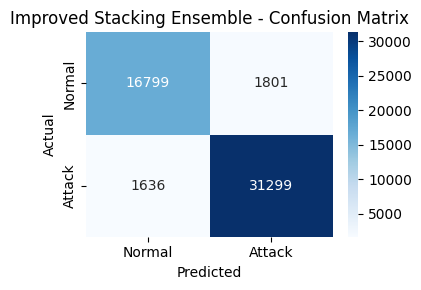

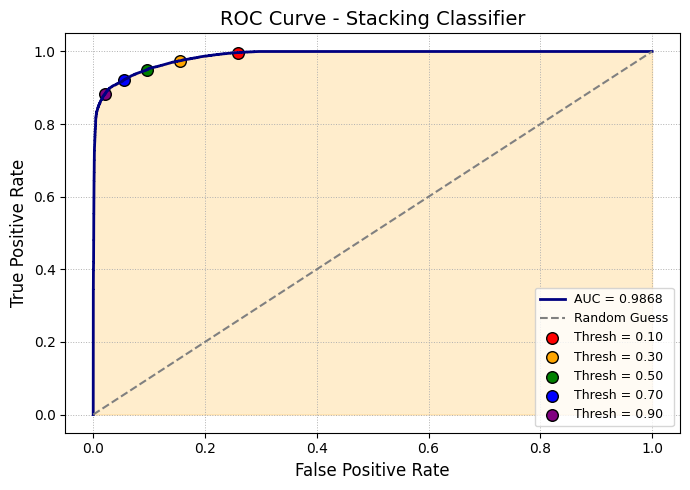

In [ ]:
# === STEP 1: IMPORT LIBRARIES ===
import torch
import random
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, log_loss, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

# === STEP 2: SET RANDOM SEED ===
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# === STEP 3: LOAD DATA ===
train_df = pd.read_csv("/content/UNSW_NB15_training-set.csv")
test_df = pd.read_csv("/content/UNSW_NB15_testing-set.csv")

# === STEP 4: COMBINE & FILTER FEATURES ===
df = pd.concat([train_df, test_df], ignore_index=True)
iot_features = [
    'dur', 'proto', 'service', 'state',
    'spkts', 'dpkts', 'sbytes', 'dbytes',
    'rate', 'sttl', 'dttl',
    'sload', 'dload', 'sloss', 'dloss',
    'sinpkt', 'dinpkt', 'sjit', 'djit',
    'ct_state_ttl', 'ct_dst_ltm', 'ct_srv_dst',
    'is_sm_ips_ports', 'label'
]
missing = set(iot_features) - set(df.columns)
if missing:
    raise ValueError(f"Missing features in dataset: {missing}")
df = df[iot_features]

# === STEP 5: CLEAN, ENCODE, SCALE ===
df.dropna(inplace=True)
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col].astype(str))
X = df.drop('label', axis=1).values
y = df['label'].values
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# === STEP 6: FEATURE SELECTION ===
selector = SelectKBest(f_classif, k=18)
X_selected = selector.fit_transform(X_scaled, y)

# === STEP 7: SPLIT ===
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, stratify=y, random_state=42
)

# === STEP 8: DEFINE BASE MODELS ===
knn = KNeighborsClassifier(n_neighbors=3)
rf = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42)
xgb_clf = xgb.XGBClassifier(
    n_estimators=250,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    use_label_encoder=False,
    scale_pos_weight=1.2,
    random_state=42
)

# === STEP 9: STACKING ENSEMBLE ===
stack_model = StackingClassifier(
    estimators=[('knn', knn), ('rf', rf), ('xgb', xgb_clf)],
    final_estimator=LogisticRegression(),
    cv=5,
    n_jobs=-1,
    passthrough=True
)

# === STEP 10: TRAIN ===
stack_model.fit(X_train, y_train)

# === STEP 11: EVALUATE ===
y_pred = stack_model.predict(X_test)
y_prob = stack_model.predict_proba(X_test)[:, 1]  # Probabilities for positive class

print("📊 Improved Evaluation Metrics:")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"Log Loss : {log_loss(y_test, y_prob):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")

# === STEP 12: CONFUSION MATRIX ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.title("Improved Stacking Ensemble - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# === STEP 13: ROC CURVE WITH THRESHOLDS ===
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_val = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='navy', lw=2, label=f'AUC = {auc_val:.4f}')
plt.fill_between(fpr, tpr, alpha=0.2, color='orange')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')

# Mark thresholds
for mark, color in zip([0.1, 0.3, 0.5, 0.7, 0.9], ['red', 'orange', 'green', 'blue', 'purple']):
    idx = np.argmin(np.abs(thresholds - mark))
    plt.scatter(fpr[idx], tpr[idx], s=70, edgecolors='black', color=color, label=f'Thresh = {thresholds[idx]:.2f}')

plt.title("ROC Curve - Stacking Classifier", fontsize=14)
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.grid(True, linestyle=':', linewidth=0.7)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()


In [ ]:
93,93